# Latihan Praktikum Bab 3: Imputasi dan Imbalanced Data
Dataset: Telco Customer Churn. Jalankan dari atas ke bawah (**Shift+Enter** pada tiap sel), atau **Runtime → Run all**.

## Persiapan

In [1]:
!pip install -q imbalanced-learn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [3]:
import os
# Baca dari folder data/ jika ada (repositori lokal); jika tidak (misalnya di Colab), ambil dari internet
lokal = "../data/Telco-Customer-Churn.csv"
url = lokal if os.path.exists(lokal) else "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna().drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df = pd.get_dummies(df, drop_first=True)

X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Distribusi kelas (data latih):")
print(y_train.value_counts())

Distribusi kelas (data latih):
Churn
0    4130
1    1495
Name: count, dtype: int64


---
# Praktikum 1: Perbandingan Strategi Imputasi
Dataset belum punya missing value (selain 11 baris `TotalCharges` yang sudah dibuang), jadi kita **membuat missing value buatan** pada 3 kolom numerik (`tenure`, `MonthlyCharges`, `TotalCharges`). Lalu bandingkan (a) mean imputation dan (b) KNN Imputer memakai Logistic Regression.

Eksperimen diulang 5 kali dengan pola missing value acak yang berbeda supaya hasilnya tidak kebetulan.

In [4]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

def buat_missing(data, frac, seed):
    data = data.copy().astype(float)
    rng = np.random.RandomState(seed)
    for col in num_cols:
        data.loc[rng.rand(len(data)) < frac, col] = np.nan
    return data

def jalankan(frac, n_ulang=5):
    hasil = {"Mean": [], "KNN": []}
    for seed in range(n_ulang):
        Xtr = buat_missing(X_train, frac, seed)
        Xte = buat_missing(X_test, frac, seed + 100)
        for nama, imp in [("Mean", SimpleImputer(strategy="mean")),
                          ("KNN", KNNImputer(n_neighbors=5))]:
            model = make_pipeline(StandardScaler(), imp,
                                  LogisticRegression(max_iter=1000))
            model.fit(Xtr, y_train)
            hasil[nama].append(f1_score(y_test, model.predict(Xte)))
    return hasil

baris = []
for frac in [0.1, 0.3]:
    h = jalankan(frac)
    for nama, skor in h.items():
        baris.append({"Missing value": f"{int(frac*100)}%", "Imputasi": nama,
                      "F1 rata-rata": round(np.mean(skor), 4),
                      "Std": round(np.std(skor), 4)})

# Pembanding: data lengkap tanpa missing value
m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("F1 data lengkap (tanpa missing):", round(f1_score(y_test, m.predict(X_test)), 4))
pd.DataFrame(baris)

F1 data lengkap (tanpa missing): 0.6091


,Missing value,Imputasi,F1 rata-rata,Std
0,10%,Mean,0.5878,0.0065
1,10%,KNN,0.6027,0.0036
2,30%,Mean,0.5765,0.0060
3,30%,KNN,0.5906,0.0084


**Kesimpulan Praktikum 1 (isi/sesuaikan dengan output Anda):** KNN Imputer memberi F1 sedikit lebih tinggi daripada mean imputation di kedua tingkat missing value, dan hasilnya lebih dekat ke F1 data lengkap. Alasannya KNN memanfaatkan kemiripan antar pelanggan, sedangkan mean mengisi semua nilai kosong dengan angka yang sama. Selisihnya kecil (sekitar 0,01 sampai 0,015), tetapi konsisten pada semua pengulangan. Kekurangan KNN: lebih lambat pada data besar.

---
# Praktikum 2: Efektivitas Penanganan Imbalanced Data
Bandingkan empat pendekatan pada Logistic Regression: baseline, SMOTE, undersampling, dan `class_weight`.

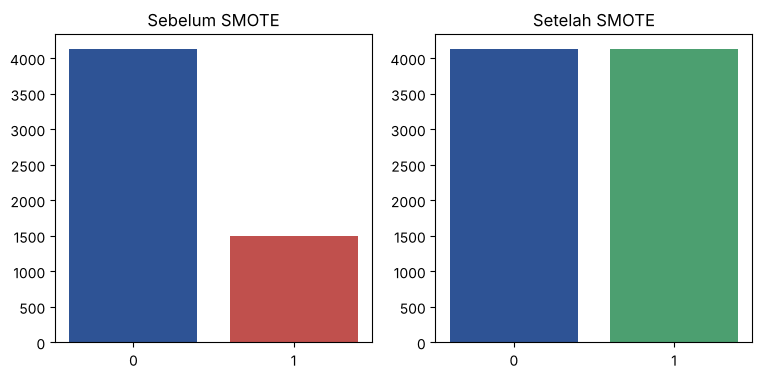

In [5]:
# Standarisasi fitur supaya Logistic Regression stabil
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# SMOTE
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_s, y_train)

# Grafik sebelum dan sesudah SMOTE (kode di buku)
before = y_train.value_counts()
after = pd.Series(y_train_sm).value_counts()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(before.index.astype(str), before.values, color=['#2E5395', '#C0504D'])
axes[0].set_title('Sebelum SMOTE')
axes[1].bar(after.index.astype(str), after.values, color=['#2E5395', '#4C9F70'])
axes[1].set_title('Setelah SMOTE')
plt.show()

In [6]:
# --- Praktikum 3.7 (kode di buku) ---
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_s, y_train)
model_rus = LogisticRegression(max_iter=1000).fit(X_train_rus, y_train_rus)

model_cw = LogisticRegression(max_iter=1000,
                              class_weight="balanced").fit(X_train_s, y_train)

# Model lain untuk dibandingkan
model_base = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
model_sm = LogisticRegression(max_iter=1000).fit(X_train_sm, y_train_sm)

In [7]:
# Bandingkan F1-Score keempat pendekatan
models = {"Baseline": model_base, "SMOTE": model_sm,
          "Undersampling": model_rus, "class_weight": model_cw}
rows = []
for nama, mdl in models.items():
    pred = mdl.predict(X_test_s)
    rows.append({"Pendekatan": nama,
                 "Akurasi": round(accuracy_score(y_test, pred), 3),
                 "Precision": round(precision_score(y_test, pred), 3),
                 "Recall": round(recall_score(y_test, pred), 3),
                 "F1": round(f1_score(y_test, pred), 3)})
hasil = pd.DataFrame(rows)
hasil

,Pendekatan,Akurasi,Precision,Recall,F1
0,Baseline,0.804,0.648,0.575,0.609
1,SMOTE,0.732,0.497,0.781,0.608
2,Undersampling,0.724,0.488,0.794,0.605
3,class_weight,0.726,0.491,0.797,0.608


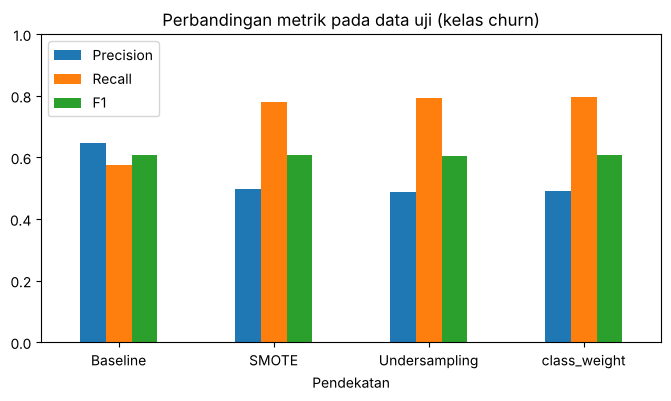

In [8]:
hasil.set_index("Pendekatan")[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(8, 4))
plt.title("Perbandingan metrik pada data uji (kelas churn)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

**Kesimpulan Praktikum 2 (isi/sesuaikan dengan output Anda):**

- Skor **F1 keempat pendekatan hampir sama** (sekitar 0,61). Pada kasus ini, pernyataan di buku bahwa F1 model SMOTE "jauh lebih tinggi" dari baseline tidak terbukti.
- Perbedaan nyata ada pada **recall dan akurasi**. Baseline punya akurasi tertinggi (sekitar 0,80) tetapi recall churn rendah (sekitar 0,58), artinya banyak pelanggan churn yang tidak terdeteksi. SMOTE, undersampling, dan class_weight menaikkan recall menjadi sekitar 0,78 sampai 0,80, dengan harga precision dan akurasi turun.
- Ketiga teknik penanganan hasilnya sangat mirip. Yang paling sederhana adalah **class_weight** karena tidak mengubah data dan tidak perlu library tambahan.
- Untuk tujuan bisnis mendeteksi pelanggan yang akan churn, **recall** lebih penting, jadi memakai class_weight, SMOTE, atau undersampling lebih berguna daripada baseline. Jika yang diutamakan F1 saja, keempatnya setara.